In [250]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import *

In [251]:
np.random.seed(42)
n = 100

# Input features
study_hours = np.random.randint(1, 8, n)
attendance = np.random.randint(50, 101, n)
previous_score = np.random.randint(30, 96, n)
assignments_completed = np.random.randint(0, 11, n)

# Numerical target for regression
noise = np.random.normal(0, 5, n)

final_score = (
    3 * study_hours
    + 0.20 * attendance
    + 0.45 * previous_score
    + 1.2 * assignments_completed
    + noise
)

final_score = np.clip(final_score, 0, 100).round(2)

# Categorical target for classification
passed = (final_score >= 50).astype(int)

# Create the dataset
df = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance': attendance,
    'Previous_Score': previous_score,
    'Assignments': assignments_completed,
    'Final_Score': final_score,
    'Passed': passed
})

In [252]:
df.head(5)

,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score,Passed
0,7,57,73,10,75.29,1
1,4,63,59,2,55.74,1
2,5,72,91,5,84.67,1
3,7,89,91,6,83.25,1
4,3,70,30,5,41.96,0


In [253]:
df.tail(5)

,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score,Passed
95,6,94,49,7,68.60,1
96,4,55,37,4,53.52,1
97,6,77,36,4,56.42,1
98,7,77,46,6,64.75,1
99,7,93,62,3,71.51,1


In [254]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     100 non-null    int32  
 1   Attendance      100 non-null    int32  
 2   Previous_Score  100 non-null    int32  
 3   Assignments     100 non-null    int32  
 4   Final_Score     100 non-null    float64
 5   Passed          100 non-null    int32  
dtypes: float64(1), int32(5)
memory usage: 2.9 KB
None


In [255]:
df.isnull().sum()

Study_Hours       0
Attendance        0
Previous_Score    0
Assignments       0
Final_Score       0
Passed            0
dtype: int64

In [256]:
X = df.iloc[:,0:4]
X

,Study_Hours,Attendance,Previous_Score,Assignments
0,7,57,73,10
1,4,63,59,2
2,5,72,91,5
3,7,89,91,6
4,3,70,30,5
...,...,...,...,...
95,6,94,49,7
96,4,55,37,4
97,6,77,36,4
98,7,77,46,6


In [257]:
y = df[["Passed"]]
y

,Passed
0,1
1,1
2,1
3,1
4,0
...,...
95,1
96,1
97,1
98,1


In [258]:
x_train,x_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=42
)

In [259]:
model = DecisionTreeClassifier(criterion = 'entropy', random_state=0)

model.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [260]:
prect = model.predict(x_test)

prect

array([1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0])

In [261]:
from sklearn.metrics import *

acc = accuracy_score(y_test,prect) * 100

acc

85.0

In [262]:
print("Confusion Matrix:\n", confusion_matrix(y_test, prect))
print(classification_report(y_test, prect, zero_division=0))


Confusion Matrix:
 [[ 5  3]
 [ 0 12]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.77         8
           1       0.80      1.00      0.89        12

    accuracy                           0.85        20
   macro avg       0.90      0.81      0.83        20
weighted avg       0.88      0.85      0.84        20



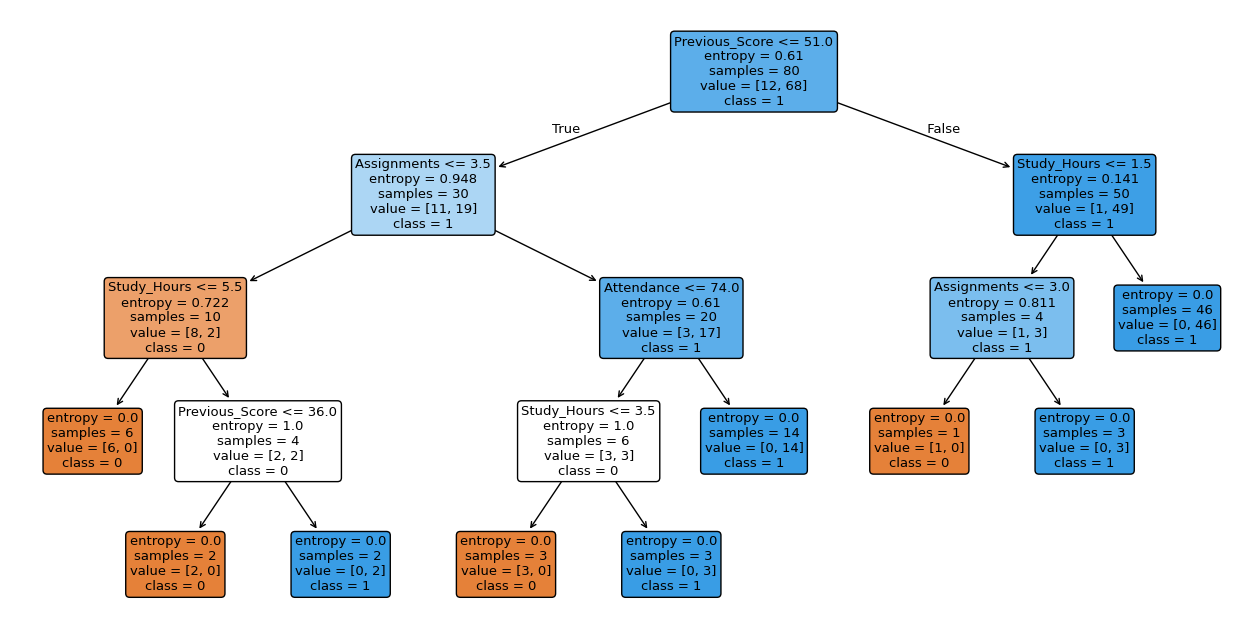

In [263]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True
)

plt.show()

<h1>End of Decision Tree</h1>

<h1>Logistic Regression

In [264]:
print(df.min(), df.max())

Study_Hours        1.00
Attendance        50.00
Previous_Score    30.00
Assignments        0.00
Final_Score       33.28
Passed             0.00
dtype: float64 Study_Hours         7.00
Attendance        100.00
Previous_Score     95.00
Assignments        10.00
Final_Score        88.71
Passed              1.00
dtype: float64


In [265]:
X = df[["Attendance" , "Final_Score"]]
X

,Attendance,Final_Score
0,57,75.29
1,63,55.74
2,72,84.67
3,89,83.25
4,70,41.96
...,...,...
95,94,68.60
96,55,53.52
97,77,56.42
98,77,64.75


In [266]:
y = df[["Passed"]]

y

,Passed
0,1
1,1
2,1
3,1
4,0
...,...
95,1
96,1
97,1
98,1


In [267]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42
)

In [268]:
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()

x_train = sc_x.fit_transform(x_train)
x_test = sc_x.transform(x_test)

In [269]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

model.fit(x_train, y_train)


C:\Users\neelp\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [270]:
y_pred = model.predict(x_test)
y_pred

array([1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0])

In [271]:
from sklearn.metrics import *

acc = accuracy_score(y_test,y_pred) * 100

acc

85.0

In [272]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test,y_pred))

[[ 5  3]
 [ 0 12]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.77         8
           1       0.80      1.00      0.89        12

    accuracy                           0.85        20
   macro avg       0.90      0.81      0.83        20
weighted avg       0.88      0.85      0.84        20



<h1>End of Logistic Regression

<h1>Linear Regression

In [273]:
df.head(10)

,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score,Passed
0,7,57,73,10,75.29,1
1,4,63,59,2,55.74,1
2,5,72,91,5,84.67,1
3,7,89,91,6,83.25,1
4,3,70,30,5,41.96,0
5,5,65,56,5,56.77,1
6,5,94,91,5,88.71,1
7,7,67,32,2,49.03,0
8,2,96,56,5,52.74,1
9,3,73,38,7,46.21,0


In [274]:
X = df[["Attendance"]]
X

,Attendance
0,57
1,63
2,72
3,89
4,70
...,...
95,94
96,55
97,77
98,77


In [275]:
y = df[["Final_Score"]]
y = sc_x.fit_transform(y)

In [276]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [277]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train, y_train)


LinearRegression()

In [278]:
y_pred = model.predict(x_test)

In [279]:
# print("Actual values:", y_test.values)
# print("Predicted values:", y_pred)

In [280]:
# 8. Evaluate regression performance
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

# Regression equation
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

MSE: 1.2045927404785688
MAE: 0.9620872815304784
RMSE: 1.0975394026997705
R2 Score: -0.02088461812380582
Slope: [0.00576321]
Intercept: [-0.39667509]


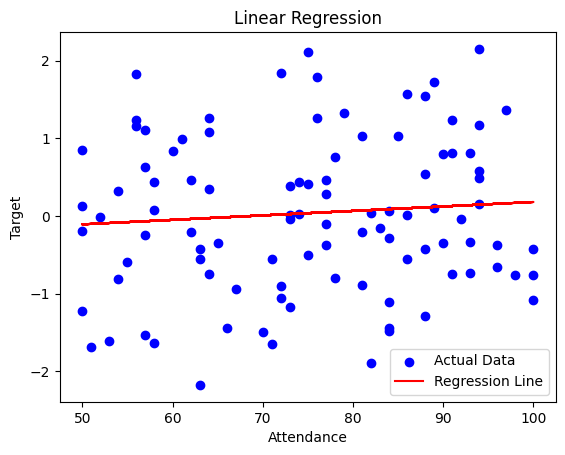

In [281]:
plt.scatter(X, y, color='blue', label='Actual Data')

y_line = model.predict(X)

plt.plot(X, y_line, color='red', label='Regression Line')

plt.xlabel('Attendance')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.legend()
plt.show()

<h1>End of Linear 

<h1>Multiple Linear Regression</h1>

In [285]:
df.head(5)

,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score,Passed
0,7,57,73,10,75.29,1
1,4,63,59,2,55.74,1
2,5,72,91,5,84.67,1
3,7,89,91,6,83.25,1
4,3,70,30,5,41.96,0


In [288]:

X = df[['Attendance', 'Assignments']]
y = df['Final_Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# 8. Evaluate regression performance
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

# Regression equation
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

MSE: 141.13933353807562
MAE: 10.52986520496152
RMSE: 11.880207638676843
R2 Score: 0.26979603988549394
Slope: 0.059655260043973604
Intercept: 51.803502589035524


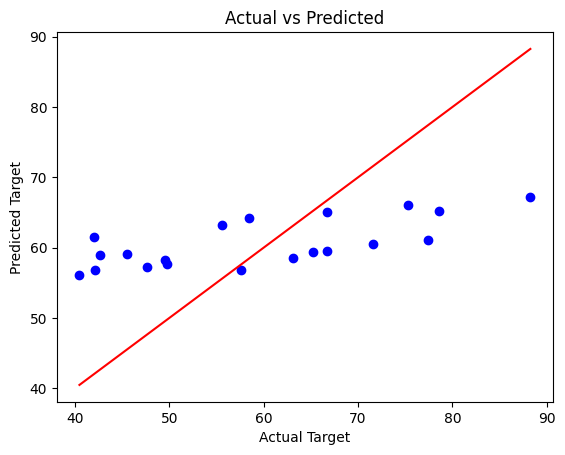

In [291]:

import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

plt.scatter(y_test, y_pred, color='blue')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Actual Target')
plt.ylabel('Predicted Target')
plt.title('Actual vs Predicted')
plt.show()
